# 02 · Make it robust: augmentation, learning curves and the confusion matrix

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/FashionNet/blob/main/notebooks/02_augmentation_curves_confusion.ipynb)

**After this notebook you will be able to** tell when a network is memorising instead of learning, try data
augmentation and judge honestly whether it helped, and read a confusion matrix to see *which* classes get mixed up.

*Time: about 30 minutes (the training cells take roughly six minutes on a laptop CPU in total).
Prerequisite: notebook 01 (pixels, convolution, a first CNN).*

## 1 · The big question

In notebook 01 the CNN scored well on pictures it had never seen. But we trained it on 20,000 pictures, which is a lot.
What if you only have **3,000**? A network with thousands of parameters can then simply *memorise* its training
pictures, like a student who learns last year's exam answers by heart and fails when the questions change a little.

Two questions for today:

1. Can we make the network more robust by showing it *slightly changed copies* of the pictures (**data augmentation**)?
2. When the final score is "86%", **what exactly is in the missing 14%**? (the confusion matrix)

## 2 · Intuition first: practice with a wobbly camera

A sneaker is still a sneaker when the photo is shifted by one pixel or mirrored. If we *show the network these variations
during training*, it cannot rely on the exact pixel positions of the few pictures it has. It has to learn what
stays the same. Think of a pianist who practises a piece at different speeds: the performance on the day becomes more
stable.

**Rules of good augmentation**

- Only change things that *do not change the label* (mirroring a sandal is fine; mirroring the digit 6 is not).
- Apply it **only to the training pictures**. Validation and test pictures stay untouched, otherwise the exam itself changes.
- Fresh random changes at *every epoch*: the network never sees exactly the same picture twice.

> **Predict:** will augmentation make the *training* accuracy go up or down? And the validation accuracy?

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/FashionNet.git"], check=True)
    os.chdir("FashionNet/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import matplotlib.pyplot as plt

from src import fashion
from src.fashion import CLASS_NAMES, save_figure, confusion_matrix

fashion.set_seed()                 # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
# A small training set on purpose: this is where memorising is a real danger.
(x_train, y_train), (x_val, y_val), (x_test, y_test) = fashion.load_fashion(n_train=3000, n_val=5000)
print("training pictures  :", len(x_train))
print("validation pictures:", len(x_val))
print("test pictures      :", len(x_test), "(locked until section 6)")

training pictures  : 3000
validation pictures: 5000
test pictures      : 10000 (locked until section 6)


**What to notice.** Same validation set as before (5,000 pictures), but only 3,000 training pictures instead of 20,000.
Let us look at what the random changes do.

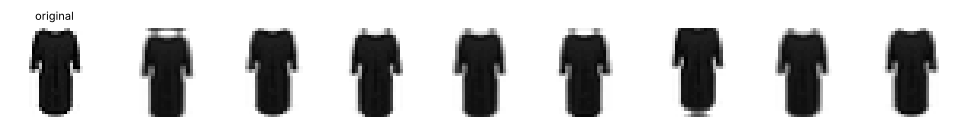

In [3]:
fashion.set_seed()
fig = fashion.plot_augmented(x_train[0], n=8, strength="mild")
save_figure(fig, "02_augmented_examples.png")
plt.show()

**What to notice.** The first picture is the original; the other eight are random variations: shifted by a pixel or two
(mirroring is hard to see because this dress is almost left-right symmetric). The garment is clearly the same. In the code (`augmentation_layers` in `src/fashion.py`)
"mild" means *mirror left-right* and *shift by up to 6% of the picture size*. A "strong" setting adds a rotation (up to 18 degrees) and a zoom (up to 20%); we will try it too.

*Figure: one training picture (left) and eight random variations of it.*

### Check yourself

1. Why must the validation pictures *not* be augmented?
2. Would mirroring left-right be a safe augmentation for a data set of handwritten letters?

<details>
<summary>Answers</summary>


1. Validation is the exam. If the exam questions are randomly changed at every epoch, the scores of different epochs
   (and different models) are no longer comparable.
2. No. A mirrored "b" looks like a "d" and the label would then be wrong. Augmentation must keep the label true.

</details>

## 3 · The experiment

We train the same small CNN as in notebook 01 for 60 epochs on the 3,000 pictures, in three ways:

- **none**: no augmentation (as in notebook 01),
- **mild**: mirror + shift,
- **strong**: mirror + shift + rotation + zoom.

Because one run can be lucky or unlucky, we repeat *none* and *mild* with **three seeds** (42, 1 and 2). The seed changes the
random starting weights and the random changes; "strong" is run once (seed 42) as a warning example.

Everything is judged on the **validation** set. The test set stays locked.

In [4]:
EPOCHS = 60
runs = {}                                     # (setting, seed) -> training history

def train(augment, seed):
    fashion.set_seed(seed)
    model = fashion.compile_model(fashion.build_cnn(augment=augment))
    return model.fit(x_train, y_train, epochs=EPOCHS, batch_size=64,
                     validation_data=(x_val, y_val), verbose=0).history

for seed in (42, 1, 2):                       # no augmentation
    runs[(None, seed)] = train(None, seed)

In [5]:
for seed in (42, 1, 2):                       # mild augmentation
    runs[("mild", seed)] = train("mild", seed)

In [6]:
runs[("strong", 42)] = train("strong", 42)    # strong augmentation, one run only

print(f"{'setting':8s} {'seed':>4s} {'train acc':>10s} {'val acc':>8s} {'val loss':>9s}")
for (setting, seed), h in runs.items():
    print(f"{str(setting):8s} {seed:4d} {h['accuracy'][-1]:10.3f} {h['val_accuracy'][-1]:8.3f} {h['val_loss'][-1]:9.3f}")

setting  seed  train acc  val acc  val loss
None       42      0.959    0.842     0.553
None        1      0.956    0.839     0.549
None        2      0.962    0.848     0.514
mild       42      0.853    0.839     0.439
mild        1      0.851    0.834     0.458
mild        2      0.851    0.849     0.426
strong     42      0.801    0.802     0.534


**What to notice.** Read the table by columns: `train acc` is the accuracy on the pictures the network practised on
(with augmentation, measured on the *augmented* pictures as they were shown during the last epoch),
`val acc` and `val loss` are on pictures it has never seen. The **gap** between train and validation accuracy is the
symptom of memorising. Loss is the quantity the network actually minimises: it punishes confident wrong answers,
so it is more sensitive than accuracy.

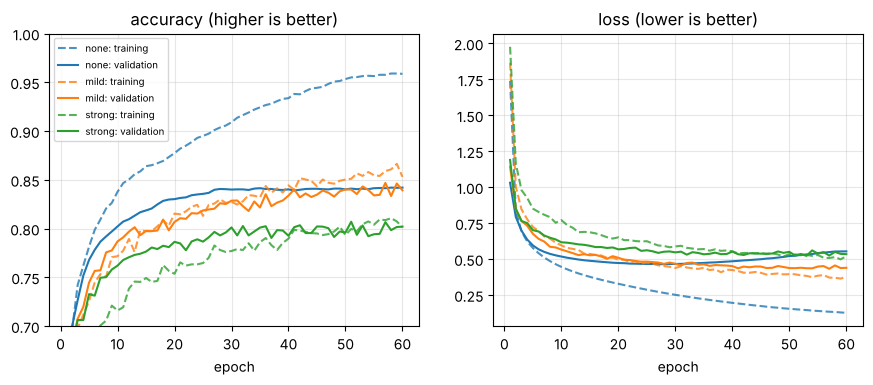

In [7]:
fig = fashion.plot_gap([runs[(None, 42)], runs[("mild", 42)], runs[("strong", 42)]],
                       ["none", "mild", "strong"])
save_figure(fig, "02_train_vs_validation.png")
plt.show()

**What to notice.** Dashed lines are measured on the training pictures, solid lines on the validation pictures.

- **none (blue):** the training accuracy keeps climbing to about 96% while the validation accuracy stops at about 84%. In the loss plot the validation loss reaches its lowest point after roughly 30 epochs and then *rises* while the training loss keeps falling. That is the classic picture of memorising.
- **mild (orange):** the training and validation curves stay close together, and the validation loss is still going down at the end.
- **strong (green):** the changes are so large that this small network has not even learned the training pictures well after 60 epochs; both accuracies stay near 80%. The augmentation is too strong for this model.

*Figure: training (dashed) and validation (solid) accuracy and loss for the three settings, seed 42.*

In [8]:
def summary(setting):
    hs = [runs[(setting, s)] for s in (42, 1, 2)]
    val_acc = np.array([h["val_accuracy"][-1] for h in hs])
    val_loss = np.array([h["val_loss"][-1] for h in hs])
    gap = np.array([h["accuracy"][-1] - h["val_accuracy"][-1] for h in hs])
    return val_acc, val_loss, gap

print(f"{'setting':8s} {'val accuracy':>22s} {'val loss':>22s} {'train - val accuracy':>24s}")
for setting in [None, "mild"]:
    a, l, g = summary(setting)
    fmt = lambda v: f"{v.mean():.3f} ({v.min():.3f}-{v.max():.3f})"
    print(f"{str(setting):8s} {fmt(a):>22s} {fmt(l):>22s} {fmt(g):>24s}")
print("(mean over seeds 42, 1, 2, with the smallest and largest value in brackets)")

setting            val accuracy               val loss     train - val accuracy
None        0.843 (0.839-0.848)    0.539 (0.514-0.553)      0.116 (0.114-0.117)
mild        0.841 (0.834-0.849)    0.441 (0.426-0.458)      0.011 (0.002-0.016)
(mean over seeds 42, 1, 2, with the smallest and largest value in brackets)


**What to notice** (averages over three seeds, validation pictures only):

- **Accuracy: no real difference.** 0.843 without versus 0.841 with mild augmentation; the ranges (0.839-0.848 and 0.834-0.849) overlap. In this experiment augmentation did **not** make the network more accurate.
- **Loss: better.** The validation loss goes from 0.539 to 0.441, and the ranges (0.514-0.553 and 0.426-0.458) do not overlap. The network is less over-confident about pictures it gets wrong.
- **Gap: much smaller.** Training accuracy minus validation accuracy is 0.116 without augmentation and 0.011 with it. (With augmentation the training accuracy is measured on changed pictures, so this comparison is not perfectly like for like.)
- **strong** (one run only): validation accuracy 0.802 and loss 0.534, worse than both.

So the honest conclusion is narrower than "augmentation helps": for this small CNN, 3,000 pictures and 60 epochs, mild augmentation removed the symptoms of memorising and improved the validation loss, but not the accuracy, and strong augmentation hurt. With a bigger network or longer training the balance could be different; we did not test that.

### Check yourself

1. The training accuracy with augmentation is *lower* than without. Is that bad?
2. We saw "strong" augmentation in one run only. Why should we be careful with a conclusion from it?

<details>
<summary>Answers</summary>


1. Not necessarily. The training pictures are now harder (they are changed), so the training accuracy drops.
   What matters is the validation accuracy and how big the gap to the training accuracy is.
2. One seed is one sample. It may point in a direction, but only repeated runs tell us whether the difference is real.

</details>

## 4 · Reading the final score: the confusion matrix

One number such as "86% accuracy" hides *where* the mistakes are. A **confusion matrix** counts, for every true class (rows),
what the network predicted (columns). A perfect model has numbers only on the diagonal.

For this part we go back to the setting of notebook 01 (20,000 training pictures, 10 epochs, same seed) and open the
locked test set once.

In [9]:
(x_tr, y_tr), (x_va, y_va), (x_te, y_te) = fashion.load_fashion(n_train=20000, n_val=5000)

fashion.set_seed()
model = fashion.compile_model(fashion.build_cnn())
model.fit(x_tr, y_tr, epochs=10, batch_size=64, validation_data=(x_va, y_va), verbose=0)

probabilities = model.predict(x_te, verbose=0)
predicted = probabilities.argmax(axis=1)
matrix = confusion_matrix(y_te, predicted)
print("test accuracy:", round(float((predicted == y_te).mean()), 4), "(notebook 01 reported 0.8670 for this setting)")

test accuracy: 0.867 (notebook 01 reported 0.8670 for this setting)


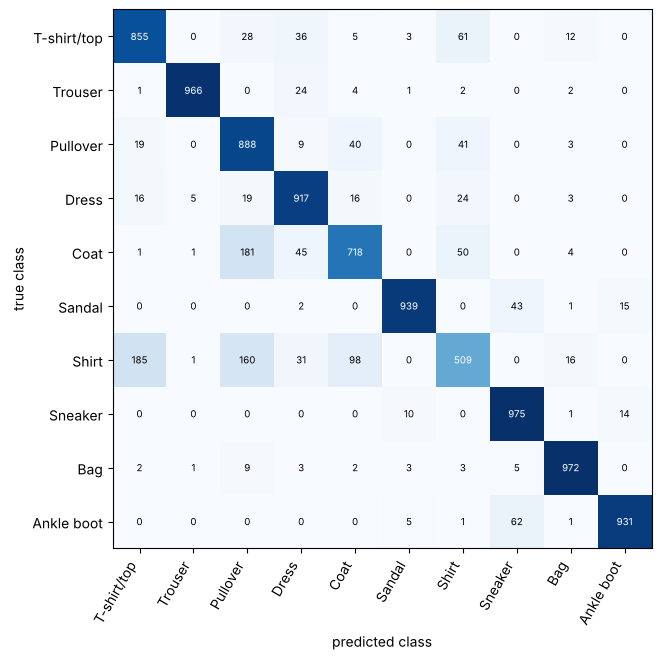

In [10]:
fig = fashion.plot_confusion(matrix)
save_figure(fig, "02_confusion_matrix.png")
plt.show()

**What to notice.** Each row sums to exactly 1,000 pictures (the test set has 1,000 of each class). The dark diagonal is the
set of correct answers. Look for the *dark cells off the diagonal*: those are the systematic confusions.

*Figure: confusion matrix of the first CNN on the 10,000 test pictures; row = true class, column = predicted class, numbers are pictures.*

In [11]:
recall = matrix.diagonal() / matrix.sum(axis=1)
print("share of each class that was recognised:")
for k in np.argsort(recall):
    print(f"  {CLASS_NAMES[k]:12s} {recall[k]:.3f}")

off_diagonal = matrix.copy(); np.fill_diagonal(off_diagonal, 0)
print("\nthe five most frequent confusions (true -> predicted):")
for flat in np.argsort(off_diagonal, axis=None)[::-1][:5]:
    i, j = divmod(flat, 10)
    print(f"  {CLASS_NAMES[i]:12s} -> {CLASS_NAMES[j]:12s} {off_diagonal[i, j]} pictures")

share of each class that was recognised:
  Shirt        0.509
  Coat         0.718
  T-shirt/top  0.855
  Pullover     0.888
  Dress        0.917
  Ankle boot   0.931
  Sandal       0.939
  Trouser      0.966
  Bag          0.972
  Sneaker      0.975

the five most frequent confusions (true -> predicted):
  Shirt        -> T-shirt/top  185 pictures
  Coat         -> Pullover     181 pictures
  Shirt        -> Pullover     160 pictures
  Shirt        -> Coat         98 pictures
  Ankle boot   -> Sneaker      62 pictures


**What to notice.**

- The easiest classes are sneaker (97.5% recognised), bag (97.2%) and trouser (96.6%); the hardest are shirt (50.9%) and coat (71.8%).
- The largest confusions are shirt predicted as T-shirt/top (185 pictures), coat as pullover (181), shirt as pullover (160) and shirt as coat (98): four of the five are upper-body clothes with sleeves. The fifth is ankle boot predicted as sneaker (62).
- The overall 86.7% hides that only about one shirt in two is recognised. If we wanted to improve the model, the shirt/T-shirt/pullover/coat group is where the effort would pay off (for example more training or a bigger network, which we have not tried here), not the classes that are already near 97%.

### Check yourself

1. A model predicts "bag" for every picture. What is its accuracy on this balanced test set, and how would its confusion matrix look?
2. Why is the confusion matrix more useful than the accuracy for deciding what to improve next?

<details>
<summary>Answers</summary>


1. 10% (1,000 of 10,000 pictures are bags). The whole "bag" column would be filled, with 1,000 in the bag row's diagonal cell and the other nine classes completely wrong.
2. It tells you *which* classes to work on (here, upper-body clothes), instead of one number that treats all mistakes alike.

</details>

## 5 · Common mistakes

- **Augmenting the validation or test set.** Only the training data is changed.
- **Augmentation that changes the label.** Think about what is still true after the change.
- **Judging by one run.** Differences of a few tenths of a percent between single runs are within the noise.
- **Reading only the accuracy.** Look at the loss, at the gap between training and validation, and at the confusion matrix.
- **Expecting augmentation to be a free lunch.** It makes the training problem harder; a model that is too small or trained for too few epochs can get *worse* (see "strong").

## 6 · Recap

- When training accuracy is far above validation accuracy the network is memorising; the curves show this early.
- Augmentation shows the network changed copies of the training pictures. It can narrow the train/validation gap, but it needs enough training time and its benefit must be measured with several seeds, not assumed.
- A confusion matrix shows *which* classes are mixed up, and tells you where the model, the data or the question needs work.

**Next:** notebook 03 opens the network up: which pixels did it look at when it said "coat"? (Grad-CAM), and compares this tutorial with the first version of the project.